# QPDK gatemon test chip — two carbon-nanotube gatemons on λ/2 transmission resonators (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/gatemon_test_chip.pic.yml`, with the
cells `qpdk/cells/gatemon.py` (`gatemon`, `gatemon_coupler`), <https://github.com/gdsfactory/quantum-rf-pdk> —
**MIT licence** (gdsfactory 2024; depth-1 clone read 2026-11-03, never executed). Spec:
`docs/designs/qpdk/gatemon_test_chip.md`. Reference in the YAML: Riechert et al., carbon-nanotube gatemon, Nat.
Commun. 2025 (doi 10.1038/s41467-025-62283-y). Two independent, mirror-image channels (a = south, b = north).
Each runs launcher → series IDC → a 600 µm `gatemon_coupler` straight where the gatemon island couples (200 µm
from its start) → meander → tail → series IDC → launcher: a **λ/2 resonator in transmission**, 11946 µm long.
Each gatemon has a gate electrode routed to its own launcher.

This notebook **rebuilds** the chip on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm chip | the same 10 × 10 mm (it does not fit the 7.5 mm die), Quantcore die frame, device ID "QPDK-GTC"; Designer = source + (5000, 5000) µm before centring |
| pads | QPDK `launcher`, 150 µm from the chip edge | `BondPad`s **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| placement | the circuit 500 µm east of the chip centre | the circuit centred in the die: shifted **−500 µm** in x (the gate pads follow along their edges) |
| substrate | Si (εr 11.45) | sapphire 650 µm, εr 10.25 |
| weak link | gate-tunable carbon nanotube (CNT contacts, nanotube, hBN, Al patch, top gate) | **no tunnel junction to replace**: no Quantcore trilayer junction applies; the CNT layers have no PDK v3 fab layer (not drawn); the LOM keeps a fixed L_J = 20 nH (assumed), C_J = 2 fF |
| cheese | none (unfilled sample; QPDK's `filled_gatemon_test_chip` is a separate variant) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) |
| components, lengths | — | kept: the six launchers, both IDC pairs, the 11946 µm λ/2 between the IDCs (600 µm coupler + 11346 µm route), the gate lines with QPDK's waypoints, the YAML targets (bare cavity 5.056 GHz, E_C/h 260 MHz, 5.4 fF coupling) |

**`Gatemon` and `GatemonCoupler`** are Quantcore re-implementations of QPDK `gatemon` / `gatemon_coupler` (MIT)
at the QPDK defaults: a 150 µm island in its pocket (60 µm side gaps, 40 µm to the line), the M1 gate feed and a
gate CPW out of the pocket; a 600 µm through-CPW whose gap opens into the pocket. Channel b is mirrored as in
QPDK (gate on the same side as a).

**Substituted / estimated:** the coupling is the cell's nominal 5.4 fF (QPDK's `coupling_capacitance`, not an
extraction); the island's C to ground is lom's analytic 51 fF (QPDK's calibrated C_Σ is 75 fF). The KQC IDC is
longer than QPDK's (port `b` 18.5 µm further east), so the coupler, the gatemon and the gate line's last waypoint
move 18.5 µm east with it. The meander is the router's KQC `Meander` on a vertical leg (5 turns, r = 50 µm);
total length exact. Launcher ports sit 110 µm further in than QPDK's (BondPad's gap also runs behind the pad).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the six launchers, the readout line of each channel (its two IDCs, the gatemon coupler and the leads), the two gatemons, the two λ/2 resonators, the declared connection of channel b, the two gate lines, and then the whole chip (sim groups, the design's targets, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `gatemon_test_chip.v1.ipynb`; both save the same `gatemon_test_chip.json`.

## Setup

The imports, the output folders and the switches. `_qpdk` holds the QPDK cell defaults shared by the QPDK
notebooks (launcher, IDC, the die box and the centring). `FULL_FAB = False` skips the fab-only corner
rounding in Fab 1 (`qcc mask` writes the full file). The segment pictures go to
`build/snapshots/gatemon_test_chip/` (not kept in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/gatemon_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 5000, 5000                              # Designer = QPDK source + (X0, Y0), before centring

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The weak link.** A gatemon's junction is a gate-tunable semiconductor weak link (here a carbon nanotube), not
a Josephson tunnel junction, so the PDK trilayer junction does not apply and nothing is sized on the PDK rule.
The LOM needs an inductance: `JJ` is a fixed L_J of 20 nH (assumed, from the spec) with C_J 2 fF; in the source
the gate voltage tunes it (LOM 3 changes it).

In [5]:
JJ = {"Lj_nH": 20.0, "Cj_fF": 2.0}               # assumed (CNT weak link, gate-tunable in the source)
L_RES = 11946.135                                # 600 coupler + 9946.135 meander + 1400 tail (QPDK)
L_CPL = 600.0                                    # gatemon_coupler length (part of the λ/2)
IDC_SHIFT = 18.5                                 # KQC IDC port b sits 18.5 µm east of QPDK cap_in o2 (−1963.5 vs −1982)
print(JJ)

{'Lj_nH': 20.0, 'Cj_fF': 2.0}


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, the qubits,
their readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (live, KLayout redraws after every cell).

**The order is fixed by the geometry here (a snap chain).** QPDK places this chip by connections: the coupler's `o1`
on the input IDC's `o2`, the gatemon's `readout` on the coupler's `qubit` port. The rebuild keeps those snaps, so the
input IDC comes first, then the coupler (Design 3), then the gatemon (Design 4); channel b's gatemon is placed at
coordinates computed from its coupler's port, so it too follows the coupler. The λ/2 itself needs no gatemon (it runs
from the coupler to the output IDC), but it is the gatemon's readout, so it is drawn after the qubits (Design 5).
Coordinates are QPDK's + (`X0`, `Y0`) until the centring in Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (device ID QPDK-GTC) |
| 2 | the six launchers: per channel an input (west), an output (east) and a gate launcher (south / north) |
| 3 | the readout line of each channel: the input and output IDCs, the 600 µm gatemon coupler snapped to the input IDC, the input and output leads |
| 4 | the two gatemons: channel a's snapped to its coupler, channel b's (mirrored) placed on its coupler |
| 5 | the two λ/2 resonators: the rest of each 11946 µm line, from the coupler to the output IDC |
| 6 | the coupling: the declared wire that joins channel b's gatemon to its coupler |
| 7 | the control routing: the two gate lines |
| 8 | the whole chip: sim groups, the design's targets, the centring of the circuit, save |

## Design 1 · The die and its frame

The source's 10 × 10 mm chip (Designer coordinates = QPDK's + (5000, 5000) µm until the centring step), the
Quantcore die frame and the device ID "QPDK-GTC". No `with_grid`: the source has no cheese, so the build draws
the PDK band.

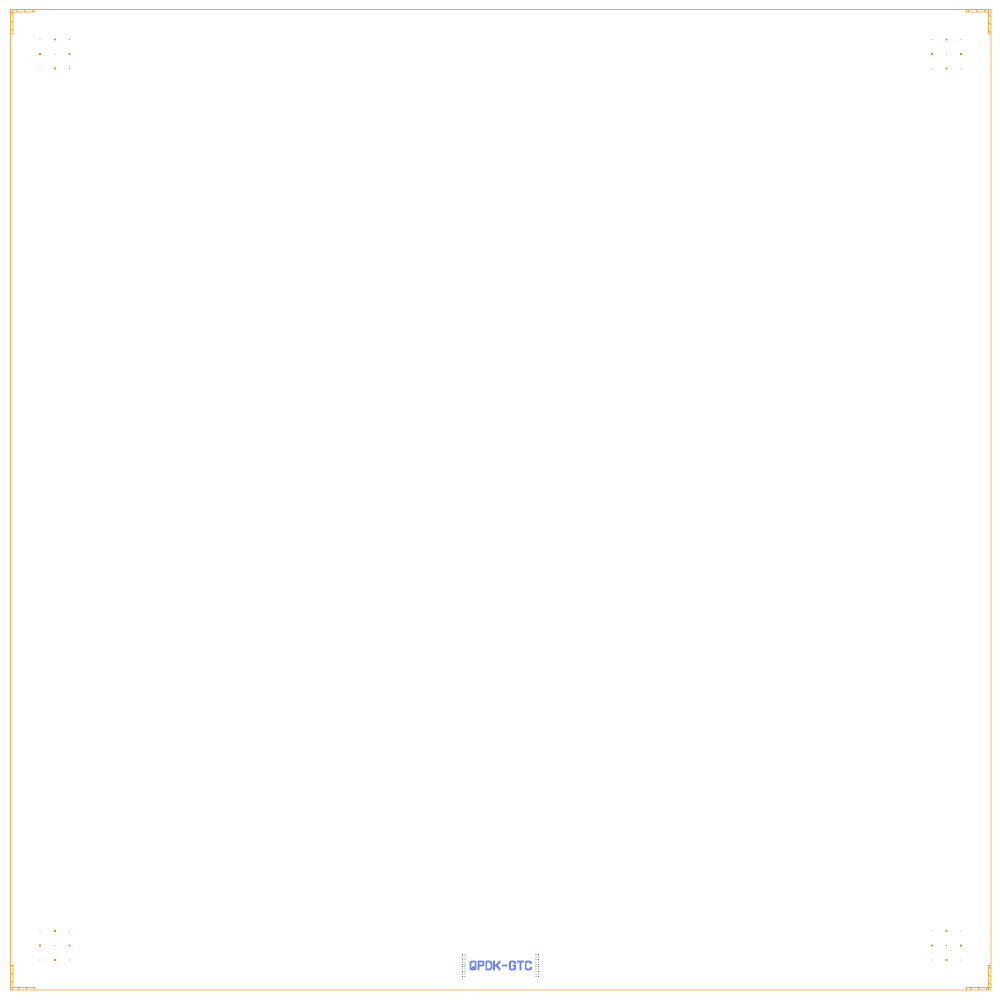

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/gatemon_test_chip/s1_die.png')

In [6]:
d = Designer("gatemon_test_chip", box=(0, 0, 10000, 10000), chip={"name_chip": "QPDK-GTC"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the six launchers and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Six launchers per chip: for each channel an input (west), an output (east) and a gate launcher (south edge for
channel a, north for b). In the source they sit 150 µm from the chip edge; the rule moves them 50 µm out.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PIN_A | `BondPad` | w | 100.0 | ✓ |
| POUT_A | `BondPad` | e | 100.0 | ✓ |
| PG_A | `BondPad` | s | 100.0 | ✓ |
| PIN_B | `BondPad` | w | 100.0 | ✓ |
| POUT_B | `BondPad` | e | 100.0 | ✓ |
| PG_B | `BondPad` | n | 100.0 | ✓ |

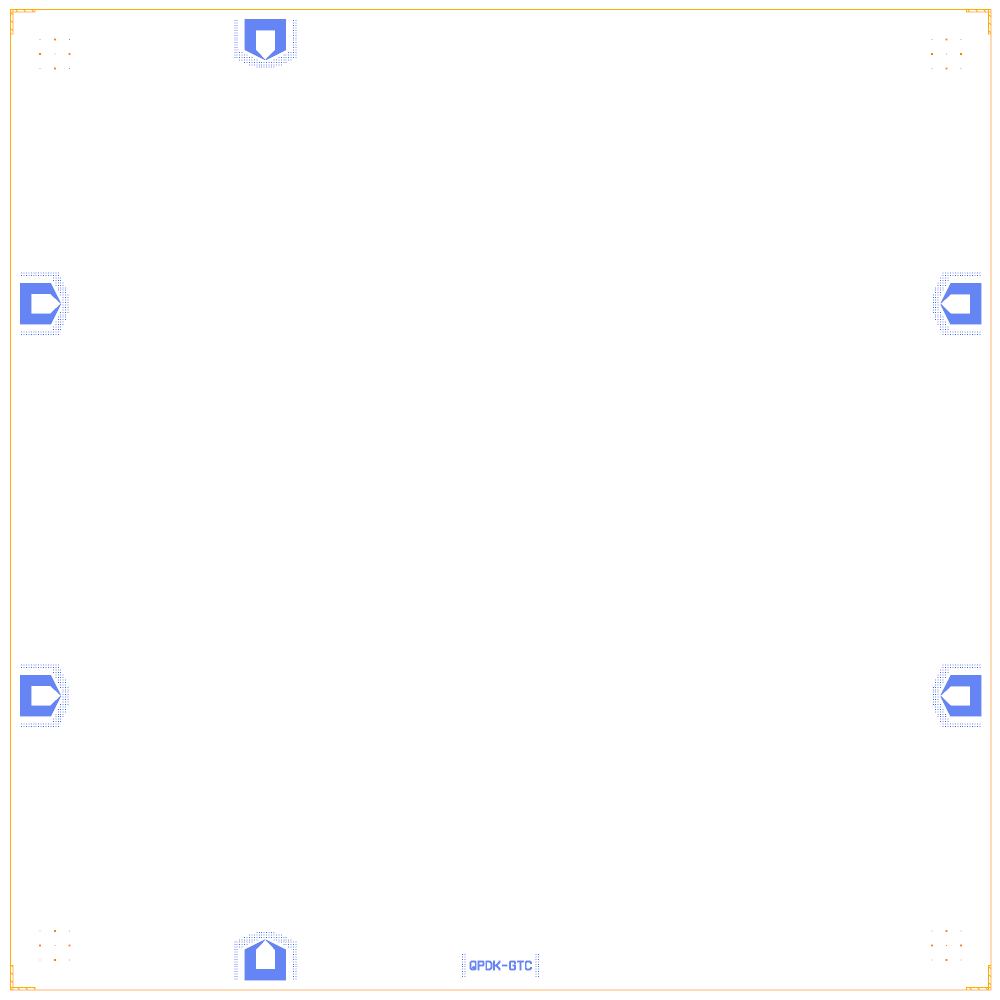

**On the chip so far:** 6 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 6 component(s) `PIN_A`, `POUT_A`, `PG_A`, `PIN_B`, `POUT_B`, `PG_B`.

WindowsPath('build/snapshots/gatemon_test_chip/s2_pads.png')

In [7]:
pads = {}
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):         # channel a south (resonator below its line), b north (mirrored)
        y = Y0 + s * 2000
        pads[f"PIN_{ch}"] = d.add(f"PIN_{ch}", "BondPad", at=(150 + QP.LAUNCHER_DEPTH, y), rot=270, edge="auto",
                                  **QP.LAUNCHER)
        pads[f"POUT_{ch}"] = d.add(f"POUT_{ch}", "BondPad", at=(9850 - QP.LAUNCHER_DEPTH, y), rot=90, edge="auto",
                                   **QP.LAUNCHER)
        pads[f"PG_{ch}"] = d.add(f"PG_{ch}", "BondPad", at=(X0 - 2400, Y0 + s * (4850 - QP.LAUNCHER_DEPTH)),
                                 rot=90 + 90 * s, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "s2_pads.png", size=(1000, 1000), width=400)

## Design 3 · Readout: the IDCs, the gatemon coupler and the leads of each channel

Per channel: the input and output IDCs (`QP.IDC`, KQC `FingerCapacitorSquare`; QPDK places the output IDC by
connection, here at its position); the `GatemonCoupler` — a 600 µm straight CPW whose gap opens into the gatemon's
pocket, the first 600 µm of the λ/2 — **snapped** with its `o1` to the input IDC (QPDK connection `coupler o1 →
cap_in o2`); the input lead (launcher → input IDC) and the output lead with QPDK's turn at x = source + 3300 µm.
None of these needs a gatemon; the gatemon snaps onto the coupler next.

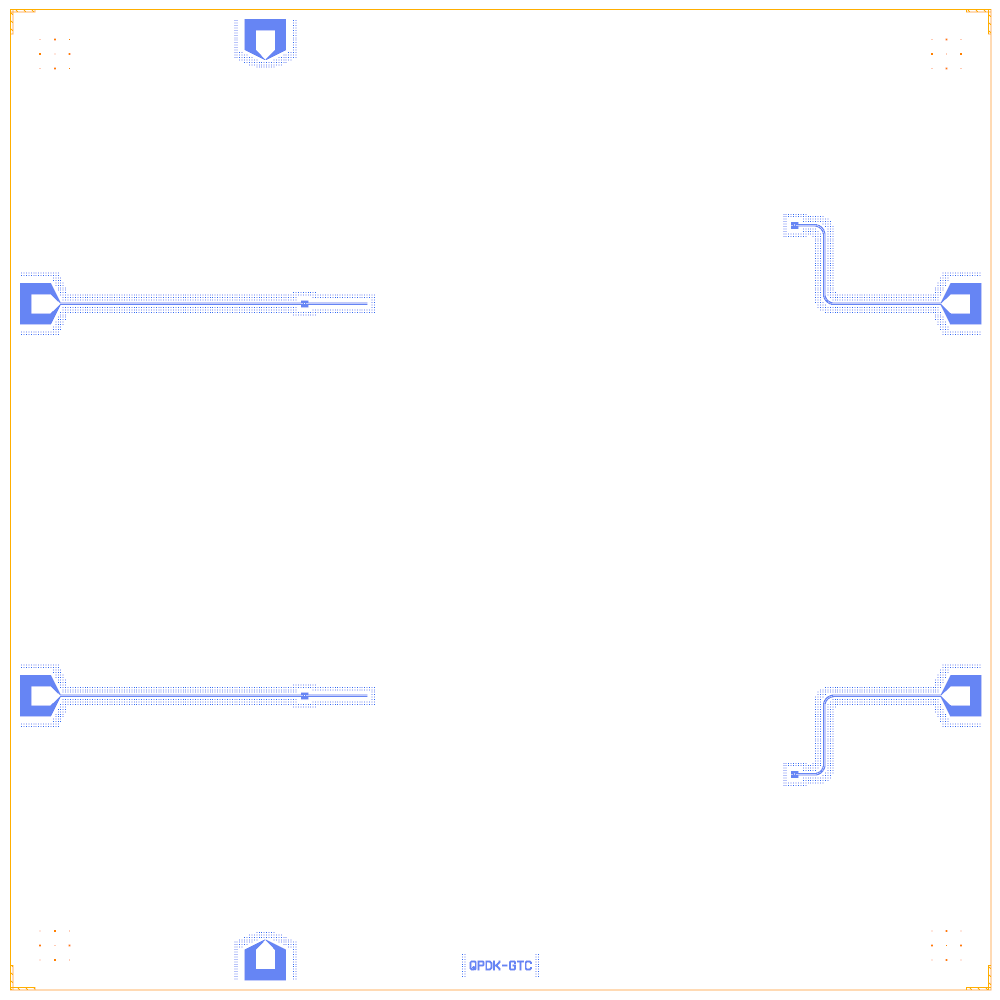

**On the chip so far:** 6 pads · 0 qubits · 6 other components · 4 routes · 0 declared couplings. **This step added** 6 component(s) `CI_A`, `CO_A`, `K_A`, `CI_B`, `CO_B`, `K_B` and 4 route(s) `IN_A`, `OUT_A`, `IN_B`, `OUT_B`.

WindowsPath('build/snapshots/gatemon_test_chip/s3_readout_line.png')

In [8]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        y = Y0 + s * 2000
        ci = d.add(f"CI_{ch}", "FingerCapacitorSquare", at=(X0 - 2000, y), **QP.IDC)
        d.add(f"CO_{ch}", "FingerCapacitorSquare", at=(X0 + 3000, y + s * 800), **QP.IDC)   # QPDK places it by connection
        k = d.add(f"K_{ch}", "GatemonCoupler", snap="o1", to=ci.b, length=L_CPL,
                  qubit_side="bottom" if s < 0 else "top")
        d.route(f"IN_{ch}", f"PIN_{ch}.a", f"CI_{ch}.a", r=QP.CPW_R)
        d.route(f"OUT_{ch}", f"CO_{ch}.b", f"POUT_{ch}.a", nodes=[(X0 + 3300, y + s * 800), (X0 + 3300, y)], r=QP.CPW_R)
layout_step(d, STEPS / "s3_readout_line.png", size=(1000, 1000), width=400)

## Design 4 · Qubit placement: the two gatemons

**`Gatemon`** (a Quantcore re-implementation of QPDK `gatemon`, MIT, at the QPDK defaults: a 150 µm island in its
pocket, 60 µm side gaps, 40 µm to the line, the M1 gate feed and a gate CPW out of the pocket), with the assumed weak
link `JJ`. Channel a's gatemon is **snapped** with its `readout` to the coupler's `qubit` port. Channel b's is
mirrored in QPDK; `Designer.add` drops `mirror` with a snap, so it is placed explicitly on `K_B.qubit` (a/2 + the
pocket's 40 µm + half the island above the line) and its connection is declared in Design 6. Gatemon ports:
`readout`, `gate`, `squid_a` / `squid_b` (weak-link reference points). The second picture zooms on channel a's
gatemon on its coupler.

<Gatemon G_A ports=['gate', 'readout', 'squid_a', 'squid_b']>


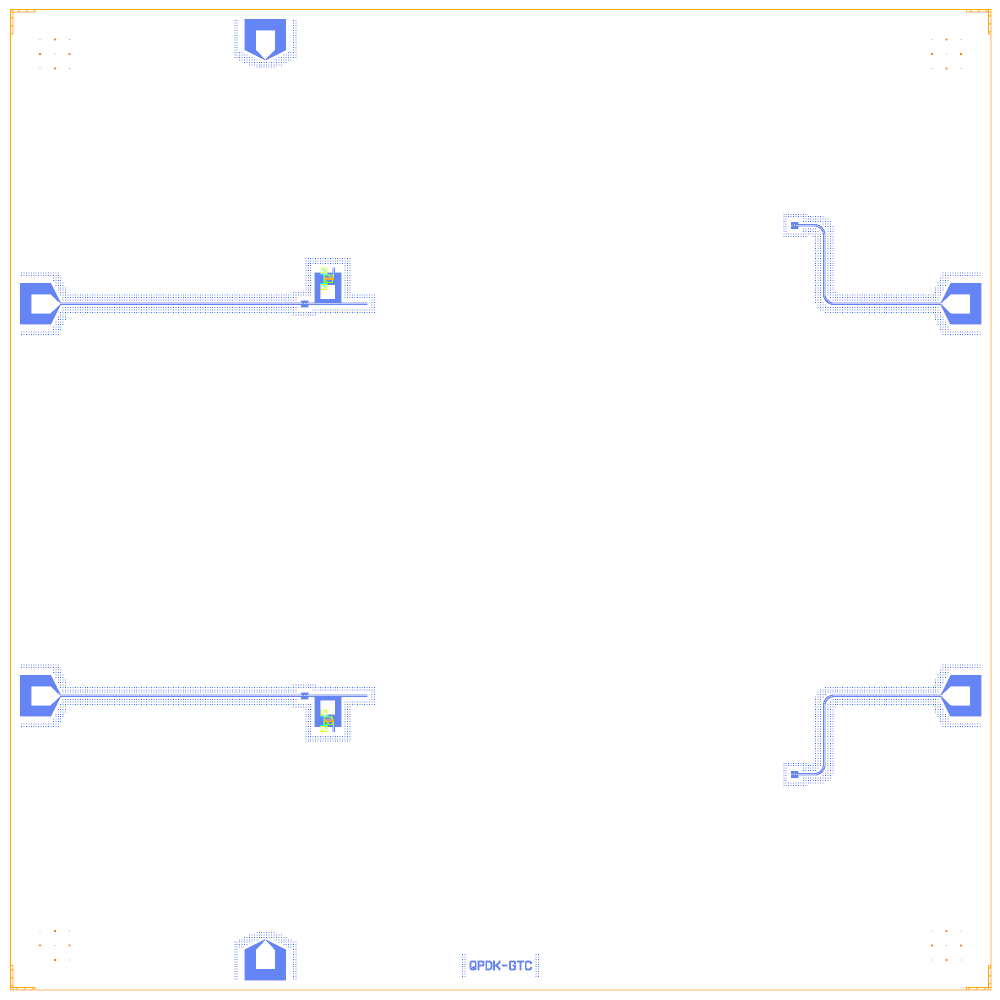

**On the chip so far:** 6 pads · 2 qubits · 6 other components · 4 routes · 0 declared couplings. **This step added** 2 component(s) `G_A`, `G_B`.

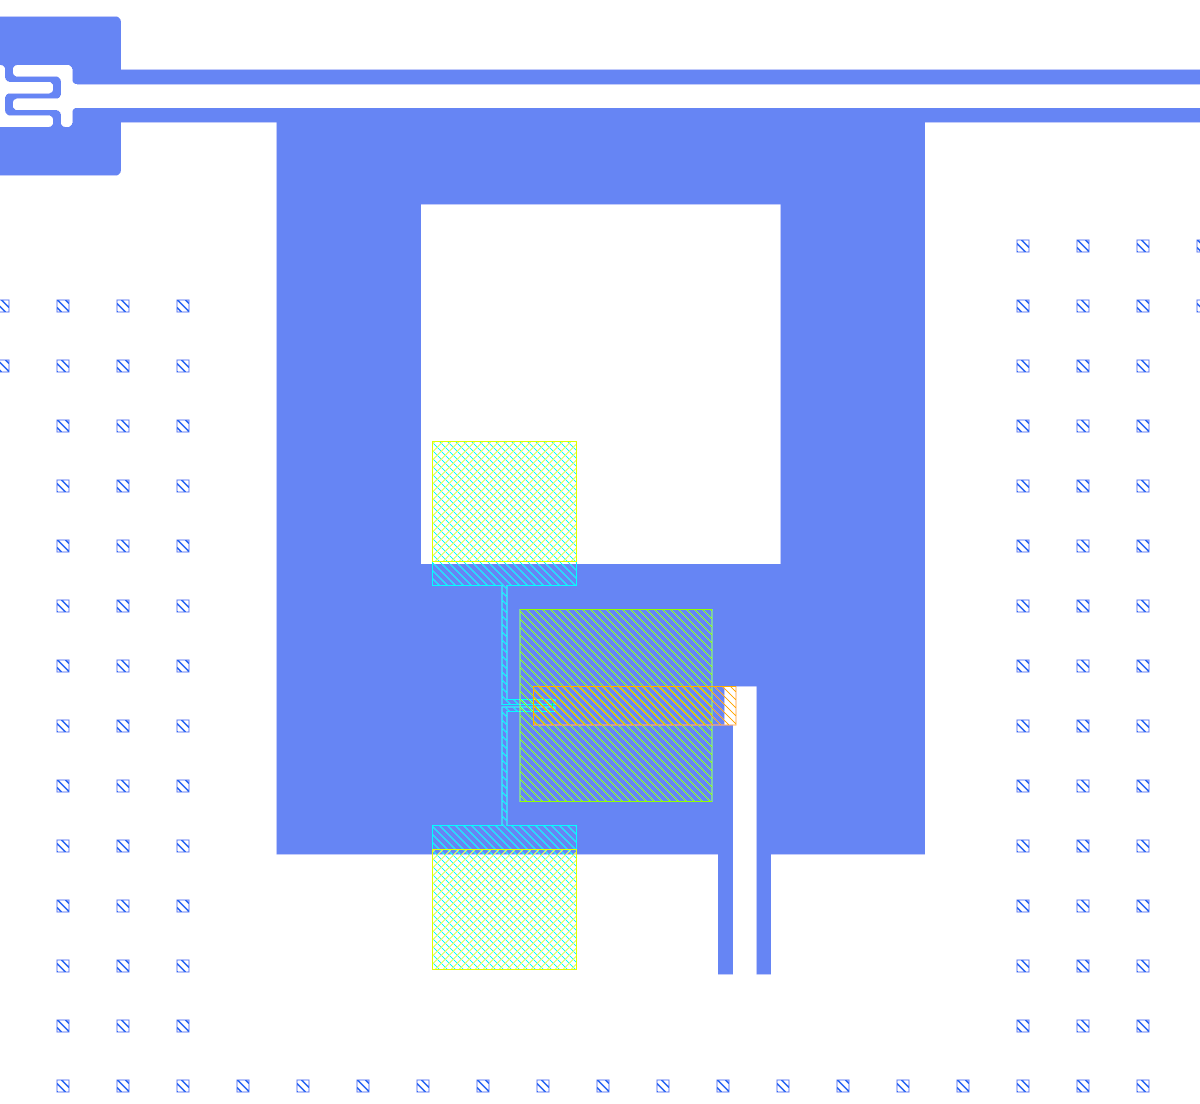

In [9]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        y = Y0 + s * 2000
        k = d[f"K_{ch}"]                         # the channel's coupler (Design 3): the gatemon snaps to its `qubit`
        if s < 0:
            d.add(f"G_{ch}", "Gatemon", snap="readout", to=k.qubit, junction=JJ)
        else:  # gatemon_b is mirrored: placed on K_B.qubit (a/2 + pocket_gap_top + island/2 above the line)
            d.add(f"G_{ch}", "Gatemon", at=(X0 - 1782 + IDC_SHIFT, y + 5 + 40 + 75), mirror=True, junction=JJ)
print(d["G_A"])
layout_step(d, STEPS / "s4_gatemons.png", size=(1000, 1000), width=400)
gx, gy = X0 - 1782 + IDC_SHIFT, Y0 - 2000 - 120   # G_A island centre (source frame, before the centring)
snap(d, STEPS / "s4_g_a.png", box=(gx - 250, gy - 300, gx + 250, gy + 160), size=(1200, 1104), width=480);

## Design 5 · Readout: the two λ/2 resonators

Per channel the rest of the λ/2 in transmission, from the coupler's far end `o2` to the output IDC: a meander on a
vertical leg at x = source + 475 µm (the middle of QPDK's meander field), 5 turns, r = 50 µm, so that coupler + route
= 11946 µm (`L_RES`). The gatemon couples to the first 600 µm (the coupler), 200 µm from its start.

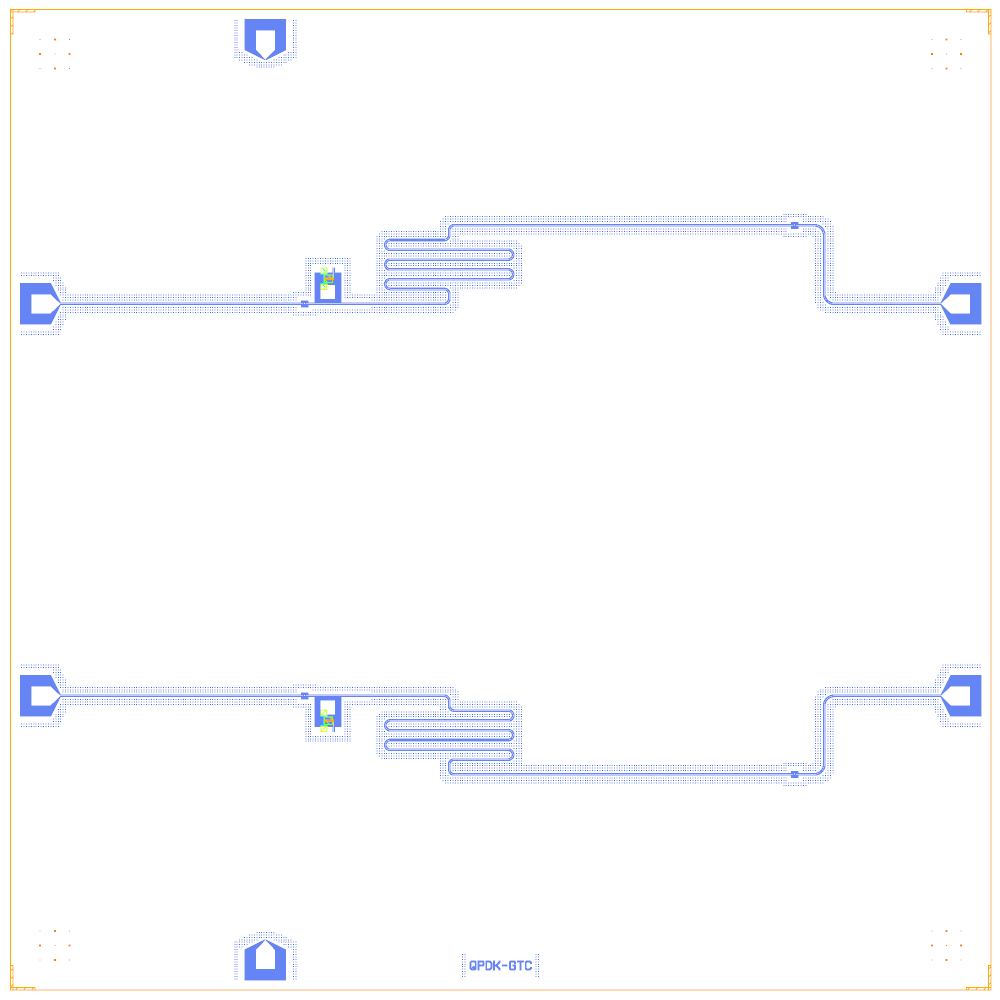

**On the chip so far:** 6 pads · 2 qubits · 6 other components · 6 routes · 0 declared couplings. **This step added** 2 route(s) `RES_A`, `RES_B`.

WindowsPath('build/snapshots/gatemon_test_chip/s5_resonators.png')

In [10]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        y = Y0 + s * 2000
        d.route(f"RES_{ch}", f"K_{ch}.o2", f"CO_{ch}.a", meander=L_RES - L_CPL, r=50,
                nodes=[(X0 - 525, y), (X0 - 525, y + s * 800)]).set(meanders=5, meander_segment=3)
layout_step(d, STEPS / "s5_resonators.png", size=(1000, 1000), width=400)

## Design 6 · Coupling: the declared connection of channel b

Each gatemon couples to its own λ/2 through the coupler (the cell's nominal 5.4 fF, QPDK's `coupling_capacitance`);
the two channels do not couple to each other. Channel a's snap already joins its gatemon to the coupler; channel b's
gatemon was placed by coordinates, so the connection QPDK makes (`gatemon_b,readout: coupler_b,qubit`) is declared
as a wire (`d.couple(..., wire=True)`): the netlist and the FEM nets see one conductor there. It is not geometry, so
the picture does not change; the line below it counts the declared coupling.

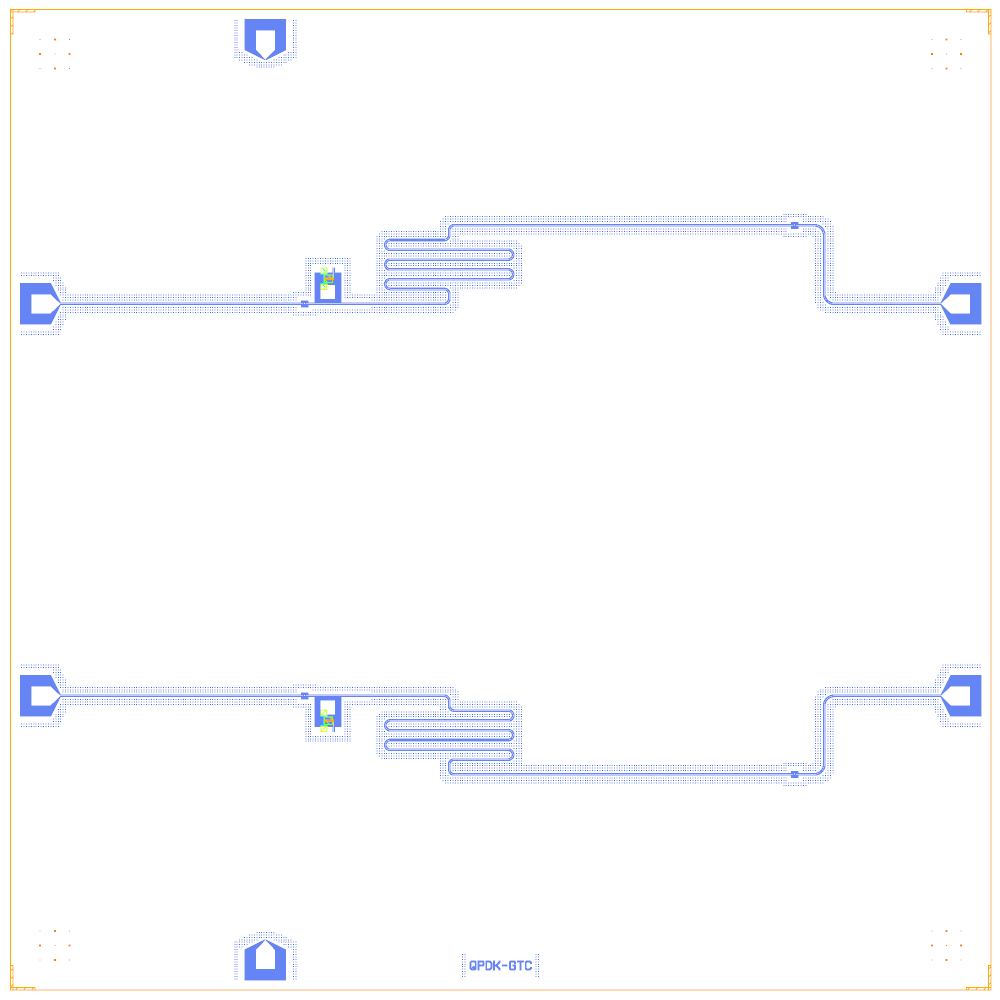

**On the chip so far:** 6 pads · 2 qubits · 6 other components · 6 routes · 1 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/gatemon_test_chip/s6_coupling.png')

In [11]:
ch = "B"                                         # channel b only (channel a's snap is its connection)
d.couple(f"W_{ch}", f"G_{ch}.readout", f"K_{ch}.qubit", wire=True, note="QPDK gatemon_b,readout: coupler_b,qubit")
layout_step(d, STEPS / "s6_coupling.png", size=(1000, 1000), width=400)

## Design 7 · Routing: the two gate lines

Each gatemon's gate CPW to its own launcher (south for channel a, north for b), with QPDK's waypoints (+ the IDC
shift). The ports printed below are before the centring.

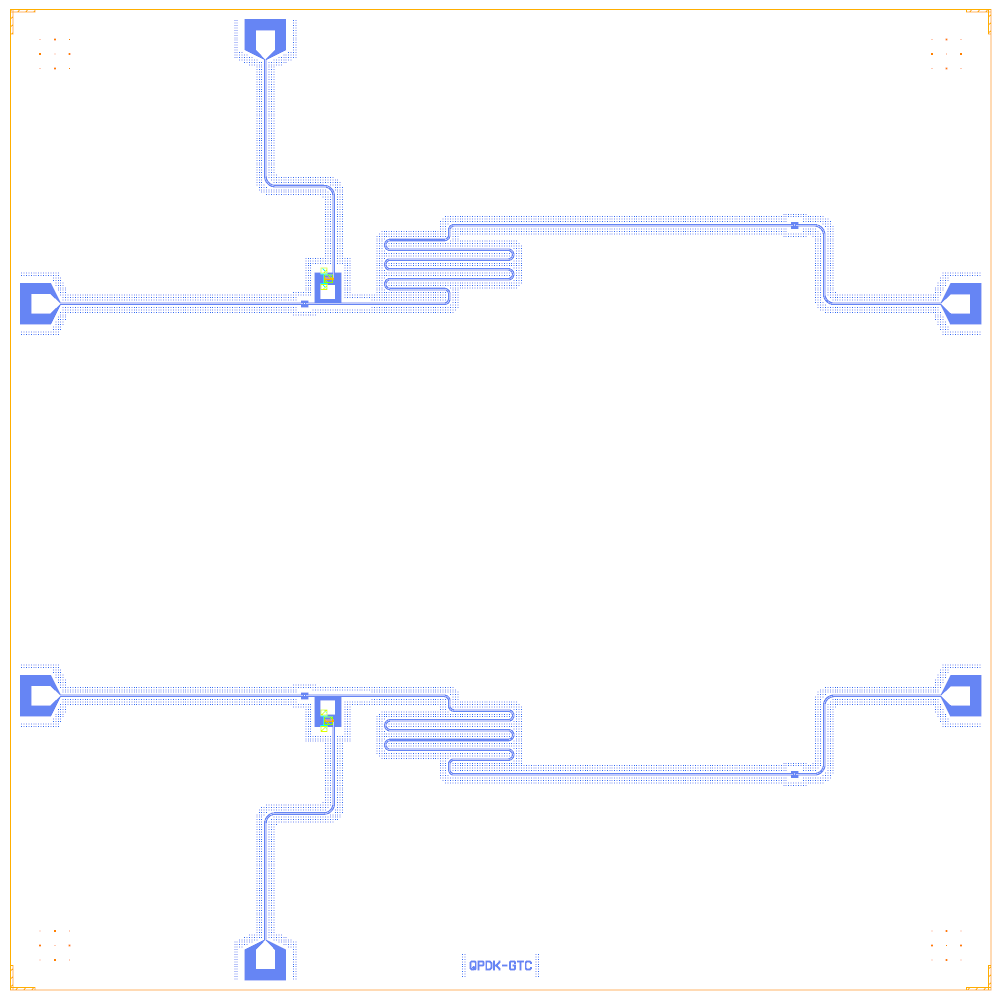

**On the chip so far:** 6 pads · 2 qubits · 6 other components · 8 routes · 1 declared couplings. **This step added** 2 route(s) `GATE_A`, `GATE_B`.

{'IN_A': 2453.5, 'OUT_A': 2167.7, 'IN_B': 2453.5, 'OUT_B': 2167.7, 'RES_A': 11346.1, 'RES_B': 11346.1, 'GATE_A': 2734.7, 'GATE_B': 2734.7}
{'K_A.o1': (3036.5, 3000.0, 180.0), 'G_A.readout': (3236.5, 2955.0, 90.0), 'G_A.gate': (3296.5, 2634.0, -90.0), 'G_B.readout': (3236.5, 7045.0, -90.0), 'G_B.gate': (3296.5, 7366.0, 90.0)}


In [12]:
with d.batch():
    for ch, s in (("A", -1), ("B", +1)):
        d.route(f"GATE_{ch}", f"PG_{ch}.a", f"G_{ch}.gate",
                nodes=[(X0 - 2400, Y0 + s * 3200), (X0 - 1722 + IDC_SHIFT, Y0 + s * 3200)], r=QP.CPW_R)
layout_step(d, STEPS / "s7_gates.png", size=(1000, 1000), width=400)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
print({p: tuple(round(v, 1) for v in port_info(d, p)) for p in ("K_A.o1", "G_A.readout", "G_A.gate", "G_B.readout", "G_B.gate")})

## Design 8 · The whole chip: sim groups, the targets, the centring, save

**Sim groups:** one per channel (the gatemon, its coupler, the λ/2 and both IDCs; 200 µm margin). **Targets:** the
YAML's `info` values, the design's own: bare cavity 5.056 GHz (`RES_A` / `RES_B`, on Si) and E_C/h 260 MHz, entered
as α = −260 MHz (`G_A` / `G_B`, |α| ≈ E_C).

**Centring.** With the pads at the die edge, the check measures the *circuit* (`QP.circuit_box`: every
instance and route except the pads and their lead routes) and `QP.center_circuit` shifts it to the die centre
when it is more than 50 µm off. Pads placed with `edge="auto"` follow the shift along their edge and stay
100 µm (`frame.pad_edge`) from it; hangers follow their feedline. Here the circuit (IDCs, couplers, gatemons, resonators) sits 500 µm east of the die centre in the source too
(QPDK's input IDC is at −2000 µm, its output IDC at +3000 µm); it is centred.

**Save.** `save_design` writes the JSON and compares it with the file it replaces (the previous run's): the segments
above changed how the chip is built (the calls of each channel are now spread over several segments), not the chip,
so it should say *same design*; the file keeps the previous key order, so `git diff` stays empty.

circuit centring shift (µm): (-500.0, 0.0)


**Same design as before:** `examples/designs/qpdk/gatemon_test_chip.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer gatemon_test_chip: 14 instances, 8 routes, live=False> → examples\designs\qpdk\gatemon_test_chip.json


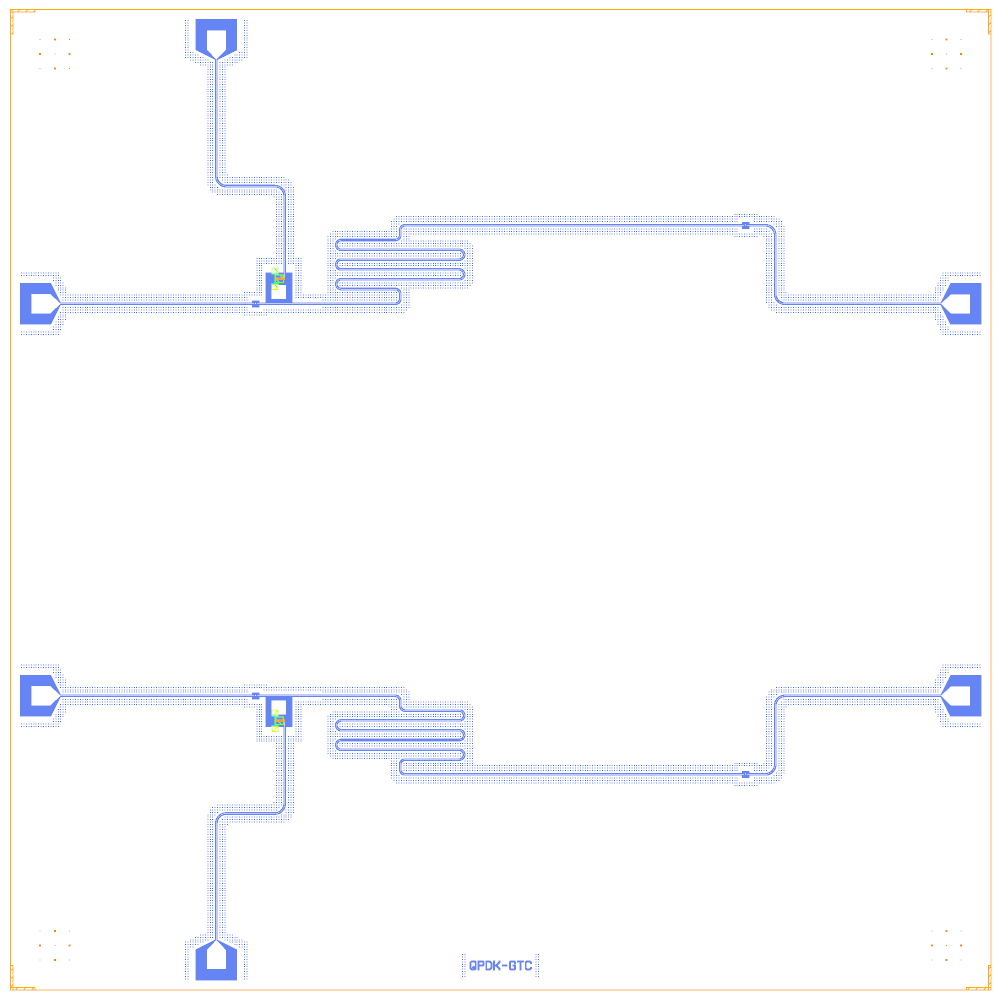

**On the chip so far:** 6 pads · 2 qubits · 6 other components · 8 routes · 1 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/gatemon_test_chip/s8_chip.png')

In [13]:
for ch in "AB":
    d.sim_group(f"CH_{ch}", [f"G_{ch}", f"K_{ch}", f"RES_{ch}", f"CI_{ch}", f"CO_{ch}"], margin_um=200)
d.targets(RES_A={"f_GHz": 5.056}, RES_B={"f_GHz": 5.056}, G_A={"alpha_MHz": -260}, G_B={"alpha_MHz": -260})
SHIFT = QP.center_circuit(d)
print("circuit centring shift (µm):", SHIFT)
rebuild(d)
DESIGN, same = save_design(d, OUT / "gatemon_test_chip.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(1000, 1000), width=400)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included, so a chip with launchers on one side reads
off-centre there) and the junction types.
Expected here (from the v1 run): `dangling_port` × 4 — the `Gatemon` `squid_a` / `squid_b` ports, reference points of the (undrawn) CNT
weak link; `overlap G_B and K_B` — channel b's gatemon is placed explicitly (mirrored) and joined by a declared
wire, so the DRC does not see the snap that exempts channel a: the pocket's etch is meant to open into the line's
gap there. **PDK design warnings:** `pdk_rn` × 2 — the R_n check reads the assumed 20 nH as a tunnel junction
(≈ 134 kΩ); a CNT weak link is not one, so the flag does not apply to this device (kept, reported).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
**Known gap (requested from lom):** the λ/2 is not in this LOM. The LOM builder joins the coupler's 600 µm line
and the 11346 µm meander route into one chain between the two IDCs, but because `GatemonCoupler`'s line is not a
resonator line and neither end is open or shorted, it treats the chain as a **wire** (node `CI_x.b` holds
`CI_x.b`, `CO_x.a` and `K_x.line`). So the simulation below has the gatemon but no resonator, g, χ or κ.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('G_A.', 'K_A.', 'CI_A',)))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each channel: the gatemon, its coupler, the λ/2 route, both IDCs, the leads and the pads. Targets from the YAML
`info` (in brackets): bare cavity 5.056 GHz (on Si), E_C/h 260 MHz (|α| ≈ E_C). f_q follows from the assumed
L_J; α from lom's rough island C (51 fF + 5.4 fF coupler + 2 fF C_J vs QPDK's calibrated 75 fF C_Σ), so |α|
comes out above 260 MHz (the v1 run: f_q 4.328 GHz, α −420.8 MHz on both channels; no resonator mode, Check 2).

In [ ]:
groups = {f"CH_{c}": [f"G_{c}", f"K_{c}", f"RES_{c}", f"CI_{c}", f"CO_{c}", f"IN_{c}", f"OUT_{c}", f"PIN_{c}", f"POUT_{c}"]
          for c in "AB"}
res = simulate_groups(d, groups)
TARGETS = {"RES_A": {"f_GHz": 5.056}, "RES_B": {"f_GHz": 5.056}, "G_A": {"alpha_MHz": -260}, "G_B": {"alpha_MHz": -260}}
display(Markdown(groups_md(res, TARGETS)))
for g, r in res.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(r)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes of each channel (QuCat; circles are qubits; filled markers are the
QuTiP dressed values; a red bar is a target), (b) the dispersive shift per resonator — empty here, since the LOM has
no λ/2 (Check 2), so there is no qubit–resonator χ. The α targets (−260 MHz) are in the table of LOM 1.

In [ ]:
plot_lom(res, STEPS / "lom.png", targets=TARGETS, title="gatemon_test_chip: LOM per channel")

## LOM 3 · One change, by hand

Before the FEM, a design step by hand. The gate voltage tunes the nanotube's L_J. Lower G_A's L_J from 20 to 15 nH (a gate step): f_q rises roughly as
1/√L_J (≈ +15 %) and α barely moves. Done on a copy (`design_copy`), so the design keeps the assumed 20 nH.

In [ ]:
d2 = design_copy(DESIGN)
d2["G_A"].set(junction={"Lj_nH": 15.0, "Cj_fF": 2.0})
after = simulate_groups(d2, {"CH_A": groups["CH_A"]})
display(Markdown("**G_A: L_J 20 → 15 nH**\n\n" + params_delta_md({"CH_A": res["CH_A"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/qpdk/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

Per channel a Q3D C-matrix job and an eigenmode / EPR job (gatemon, coupler, λ/2 and both IDCs; the in / out lines leave the box in 50 Ω).
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/qpdk/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per channel
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "CH_A", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitance of each channel as named nets: the gatemon island, the coupler's line and the rest of the λ/2, the
leads. This is the number the LOM guesses worst here — its analytic island C (≈ 51 fF) against QPDK's calibrated
C_Σ of 75 fF — and α follows from it (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept
results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same boxes in HFSS eigenmode: the weak link is a lumped L_J ‖ C_J sheet (the assumed 20 nH, 2 fF), the in / out
lines end in 50 Ω, so each mode's Q gives κ. Here the eigenmode is the only model with the λ/2: its resonator mode
(near the 5.056 GHz target) is what the f_r target needs. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) gives the gatemon's dressed f_q, α and χ to the λ/2.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 through channel a, from the input lead to the output lead. The library cannot hand the
solved eigenmode **mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest
honest thing: the same sim group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the
eigenmode's resonator mode (the 5.056 GHz target before the eigenmode is solved: the LOM has no λ/2) and a fast sweep
around it. The λ/2 sits in transmission between two IDCs, so S21 shows a **peak**, not a hanger notch: the notch fit
of `driven_md` / `driven_values` may find nothing, and then f_r and κ come from the eigenmode (Results 2).

In [ ]:
F_RES = 5.056                                    # the design's f_r target (GHz): the guess for the λ/2 mode
jobs_drv = driven_from_eigenmode(DESIGN, "CH_A", jobs_eig["CH_A"][0], keep_eig["CH_A"], f_guess=F_RES)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["CH_A"]:
    display(Markdown(driven_md(keep_drv["CH_A"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the weak link's participation p_J (≈ 1: the gatemon; ≈ 0: the λ/2), with the LOM's gatemon
frequencies and the f_r target as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {f"G_{c}": res[f"CH_{c}"].params.get(f"G_{c}.f_q_GHz") for c in "AB"}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom={**lom_f, "f_r target": F_RES})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the targets' terms: the gatemon's mode is the one its weak link participates in most, the
λ/2's the remaining mode nearest 5.056 GHz; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box. The driven run adds a notch only if its fit finds one (see Simulate 4).

In [ ]:
fem_values = {}
for c in "AB":
    keep = keep_eig.get(f"CH_{c}")
    if keep:
        fem_values[f"G_{c}"] = epr_values(keep, {f"G_{c}": f"RES_{c}"}, {f"RES_{c}": F_RES})
if keep_drv["CH_A"]:
    fem_values.setdefault("G_A", {}).update({f"driven {k}": v for k, v in
                                             driven_values(keep_drv["CH_A"], "RES_A", F_RES).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for vals in fem_values.values() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each gatemon, f_r, χ and κ "
          "of its λ/2 from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of each channel by its C-matrix values
(matched by net name) and the same LOM runs again: that moves α towards the calibrated value. **FEM directly:** the
eigenmode (pyEPR) values of Results 2, including the λ/2's f_r, which has no LOM counterpart (the LOM column says
"–"). `alpha_fem` keeps the LOM-on-Q3D α of each gatemon for the feedback.

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows, alpha_fem = [], {}
for c in "AB":
    g, est = f"CH_{c}", res[f"CH_{c}"].params
    keys = [f"G_{c}.f_q_GHz", f"G_{c}.alpha_MHz", f"RES_{c}.f_GHz", f"RES_{c}.chi_MHz", f"RES_{c}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        alpha_fem[f"G_{c}"] = on_fem.get(f"G_{c}.alpha_MHz")
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys[:2]]
    for key in keys:
        if key in fem_values.get(f"G_{c}", {}):
            rows.append((key, est.get(key), fem_values[f"G_{c}"][key], "eigenmode + pyEPR"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of the LOM next to the LOM on the Q3D "
          "C-matrix and the eigenmode, and adds the eigenmode's f_r, χ and κ of the λ/2.")

## Results 4 · Feedback: one step towards the design's targets

The design has its own targets (Design 8): α = −260 MHz and f_r = 5.056 GHz per channel. `loop.feedback` tunes
qubit–readout pairs, and here the LOM has no readout (the λ/2 is a wire, Check 2), so it has no pair to tune; the
feedback is a first-order rule per target, on channel a:

- **α → the island.** |α| ≈ E_C = e²/2C_Σ, and C_Σ grows with the island, so α ∝ s^−1 to first order in the
  island's side s (`G_A.island_size`, both sides). The rule is evaluated on the LOM; when a Q3D solve is kept, the
  LOM's α is first scaled by FEM / LOM at the drawn island (`SCALE`, from Results 3), so the step aims at the FEM
  value, not the LOM's rough C. Channel b takes the same island, but its gatemon is placed by coordinates: a bigger
  island needs its `at` moved by half the change to keep the readout edge on the line (by hand).
- **f_r → the λ/2 length.** f ∝ 1/ℓ for the whole 11946 µm line (the 600 µm coupler + the `RES_A` route), so the
  route becomes (ℓ · f / f_target) − 600 µm. It needs the eigenmode's f_r (Results 2): without one the cell says so.

Both steps work on copies (`design_copy`, saved as `build/gatemon_test_chip_rev<k>.json`); the design file keeps the
drawn island and length.

In [ ]:
import json

TARGETS_D = json.loads(Path(DESIGN).read_text(encoding="utf-8"))["targets"]   # the design's own targets
A_T, A_TOL = TARGETS_D["G_A"]["alpha_MHz"], 5.0  # G_A's α target and the tolerance used here (MHz)
F_T, F_TOL = TARGETS_D["RES_A"]["f_GHz"], 0.010  # RES_A's f_r target and tolerance (GHz)
a_lom = res["CH_A"].params.get("G_A.alpha_MHz")
SCALE = alpha_fem["G_A"] / a_lom if alpha_fem.get("G_A") else 1.0   # FEM / LOM at the drawn island (1: LOM only)
a0 = SCALE * a_lom
S0 = float((d.data["instances"]["G_A"]["params"].get("island_size") or [150, 150])[0])   # the island side (µm)
s1 = rule_step(S0, a0, A_T, -1.0)
L0 = float(d.data["routes"]["RES_A"]["length"])  # the λ/2 route (µm); + L_CPL is the whole line
f0 = fem_values.get("G_A", {}).get("RES_A.f_GHz")
L1 = rule_step(L0 + L_CPL, f0, F_T, -1.0) - L_CPL if f0 else None
display(Markdown("| target | now | rule | knob now | knob proposed |\n|---|---|---|---|---|\n"
                 f"| `G_A.alpha_MHz` {A_T:g} ± {A_TOL:g} | {a0:.1f} ({'FEM-scaled' if SCALE != 1.0 else 'LOM'}) | "
                 f"α ∝ s^−1 | `G_A.island_size` {S0:g} µm | **{s1:.1f} µm** |\n"
                 f"| `RES_A.f_GHz` {F_T:g} ± {F_TOL:g} | {'–' if f0 is None else f'{f0:.4f} (eigenmode)'} | "
                 f"f ∝ 1/ℓ | `RES_A.length` {L0:.1f} µm | **{'–' if L1 is None else f'{L1:.1f} µm'}** |"))
if f0 is None:
    print("RES_A: no eigenmode f_r yet (RUN_FEM = True solves CH_A's eigenmode): the LOM has no λ/2, so the length "
          "rule has nothing to start from.")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): build revision k with the knob, evaluate it, step again with the exponent of the
last two points (a secant), until the value is within its tolerance or `MAX_ITER` steps are made. **α:** each
revision is evaluated on the LOM (× `SCALE`), or, with `RUN_FEM = True`, on its own Q3D C-matrix (channel a's job,
exported to `build/jobs/rev<k>/` and solved: AEDT minutes each). **f_r:** only with an eigenmode value to start from;
with `RUN_FEM = True` each revision's eigenmode is solved (minutes to tens of minutes each), else the loop stops after
the start row and says so.

In [ ]:
def alpha_of(k, it):
    """Revision it: G_A's island side k µm; its α on the LOM (× SCALE), or on its own Q3D C-matrix with RUN_FEM."""
    d2 = design_copy(DESIGN, f"_rev{it}")
    d2["G_A"].set(island_size=[k, k])
    path = d2.save(Path("build") / f"gatemon_test_chip_rev{it}.json")
    if RUN_FEM:
        job = export_sims(path, ["CH_A"], root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["CH_A"]
        if keep:
            return simulate(fill(d2.lom(select=groups["CH_A"]).model, path, keep), max_modes=2).params.get(
                "G_A.alpha_MHz"), path
    return SCALE * simulate_groups(d2, {"CH_A": groups["CH_A"]})["CH_A"].params.get("G_A.alpha_MHz"), path


def f_res_of(k, it):
    """Revision it: RES_A's route k µm; its λ/2 mode from its own eigenmode job (RUN_FEM only, else None)."""
    d2 = design_copy(DESIGN, f"_len{it}")
    d2["RES_A"].set(meander=k)
    path = d2.save(Path("build") / f"gatemon_test_chip_len{it}.json")
    if not RUN_FEM:
        return None, path
    job = export_sims(path, ["CH_A"], analysis="eigenmode_epr", root=f"build/jobs/len{it}")
    keep = fem_stage(job, RUN_FEM, KEEP / f"len{it}", force=RESOLVE, aedt=AEDT_MODE)["CH_A"]
    return (epr_values(keep, {"G_A": "RES_A"}, {"RES_A": F_T}).get("RES_A.f_GHz") if keep else None), path


hist_a = rule_iterate(alpha_of, "G_A.alpha_MHz", "G_A.island_size", S0, A_T, A_TOL, -1.0, max_iter=MAX_ITER,
                      start=(a0, DESIGN), fem=bool(RUN_FEM), bounds=(80.0, 400.0))
display(Markdown("**α → the island (channel a):**\n\n" + history_md(hist_a)))
plot_iterations(hist_a, STEPS / "iterate_alpha.png")
if f0 is not None:
    hist_f = rule_iterate(f_res_of, "RES_A.f_GHz", "RES_A.length", L0, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                          start=(f0, DESIGN), fem=True)
    display(Markdown("**f_r → the λ/2 length (channel a):**\n\n" + history_md(hist_f)))
else:
    print("f_r: no eigenmode value to start from (RUN_FEM = True): the length loop is not run.")

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `gatemon_test_chip.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/qpdk/gatemon_test_chip.json` rebuilds `build/gatemon_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
No junction layers: the CNT weak link is not a trilayer junction, and its contacts / nanotube / hBN / Al patch /
top gate have no PDK v3 fab layer, so on this mask the island has no M1 path to ground. The cheese source is
`build`: the PDK band (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/gatemon_test_chip.json`
writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The full chip (compare QPDK's render of the filled variant, shown last); channel a's gatemon on its coupler with
the gate feed; the weak-link region below the island (only the pocket etch and the gate landing are in M1); the
input IDC and the start of the coupler; the die frame's south-west corner; and the gatemon in the **fab view**
(the mask from Fab 1: 1/0 with the PDK cheese band, 3/0). Boxes are the source positions + the centring shift.

In [ ]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "gatemon_test_chip.png", size=(1600, 1600), width=640)
gx, gy = X0 - 1782 + IDC_SHIFT, Y0 - 2000 - 120   # G_A island centre (source frame)
show_snapshot(d, OUT / "gatemon_test_chip_qubit.png", box=box(gx - 250, gy - 300, gx + 250, gy + 160), size=(1200, 1104), width=480)
show_snapshot(d, OUT / "gatemon_test_chip_jj.png", box=box(gx - 110, gy - 215, gx + 90, gy - 55), size=(1000, 800), width=360)
show_snapshot(d, OUT / "gatemon_test_chip_idc.png", box=box(X0 - 2060, Y0 - 2040, X0 - 1940, Y0 - 1960), width=360)
show_snapshot(d, OUT / "gatemon_test_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "gatemon_test_chip_fab.oas", OUT / "gatemon_test_chip_fab_qubit.png",
          box=box(gx - 300, gy - 350, gx + 300, gy + 250), size=(1000, 1000), width=400);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render (of the filled gatemon variant, the only image QPDK publishes for this chip) is shown from the local clone
when present.

In [ ]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "gatemon_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/gatemon_test_chip.png")

## Summary

| | |
|---|---|
| **matches the source** | both channels: launchers, IDCs, the 600 µm gatemon coupler, the 11946 µm λ/2 between the IDCs, the gatemons (QPDK defaults), the gate lines with QPDK's waypoints, the YAML targets |
| **differs (PDK)** | the Quantcore die frame; pads 100 µm from the edge; the circuit centred (−500 µm in x); sapphire; the PDK cheese band |
| **not drawn / estimated** | the CNT weak link and its process layers (no PDK layer); L_J 20 nH assumed; the λ/2 is a wire in the LOM (lom request) |
| **PDK design warnings** | `pdk_rn` × 2 (the assumed 20 nH read as a tunnel junction; not applicable to a CNT weak link) |
| layout | built in eight segments (die, launchers, readout line with the snapped coupler, gatemons, λ/2 resonators, channel b's declared wire, gate lines, the whole chip; the snap chain keeps IDC → coupler → gatemon); the saved JSON is the v1 notebook's |
| feedback | the design's targets: α → the island side (first-order rule, LOM × FEM/LOM scale; Q3D per revision with `RUN_FEM`), f_r → the λ/2 length (needs the eigenmode); `loop.feedback` has no pair here |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the λ/2 is in the FEM only (the LOM sees a wire) |